# Flow Cytometry Analysis — Python

Lightweight Python alternative for flow cytometry analysis.  
Covers: loading CSV and .fcs data, visualization, gating, clustering, and UMAP.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Dimensionality reduction & clustering
import umap
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Flow-specific
import flowkit as fk

plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (10, 4)

## 2. Load data — CSV

In [2]:
csv_path = "../data/matrix_data.csv"
df = pd.read_csv(csv_path)
print(f"Shape: {df.shape}")
df.head()

Shape: (13982, 4)


,FSC-A,SSC-A,Alexa_488-A,PI-A
0,106737.00,34943.1,1182.820,115.2120
1,6390.56,13911.8,277.841,54.4942
2,252124.00,84884.6,4916.180,154.5880
3,262143.00,204461.0,5511.650,557.2780
4,262143.00,133109.0,4741.050,349.7930


In [3]:
df.describe()

,FSC-A,SSC-A,Alexa_488-A,PI-A
count,13982.000000,13982.000000,13982.000000,13982.000000
mean,124505.234895,60719.665134,11082.466061,663.858422
std,44495.263033,37896.108731,21429.143966,2168.966341
min,5136.560000,1004.150000,-40.202900,-149.687000
25%,107128.250000,39094.000000,2168.992500,73.315175
50%,122079.000000,50405.700000,3574.750000,116.726000
75%,139020.250000,67562.350000,6740.255000,182.421000
max,262143.000000,262143.000000,260470.000000,87389.000000


## 3. Load data — .fcs (optional)

In [4]:
fcs_path = "../data/sample.fcs"

sample = fk.Sample(fcs_path)

# Compensate with the spillover matrix in the file, if there is one, and read
# the compensated events. source="raw" would return uncompensated values.
spill = sample.metadata.get("spill")
if spill is not None:
    sample.apply_compensation(spill)
    events = sample.as_dataframe(source="comp")
    print(f"Loaded and compensated: {events.shape}")
else:
    events = sample.as_dataframe(source="raw")
    print(f"No spillover matrix in file, loaded uncompensated: {events.shape}")

events.head()

Loaded and compensated: (50000, 11)


pnn,FSC-A,FSC-H,FSC-W,SSC-A,SSC-H,SSC-W,FITC-A,PE-A,PerCP-A,APC-A,Time
pns,,,,,,,CD1a,CD83,CD11b,,
0,247373.281250,64192.0,252552.578125,262143.000000,77884.0,220581.937500,74931.315645,22443.681628,36564.385224,-2758.041287,0.223
1,206184.875000,65115.0,207517.953125,247423.453125,55503.0,262143.000000,69545.784307,13257.602665,23360.579830,-1586.260312,0.224
2,143285.125000,63755.0,147287.812500,189480.734375,59750.0,207829.453125,820.068566,1298.602619,4058.768748,222.529013,0.224
3,89929.835938,54289.0,108560.515625,200890.812500,74655.0,176352.265625,823.045703,3279.302112,6449.102086,-110.873740,0.224
4,90663.757812,50301.0,118123.695312,120292.921875,57351.0,137460.828125,14072.258436,3373.706306,7390.344789,-509.768378,0.225


## 4. Visualization

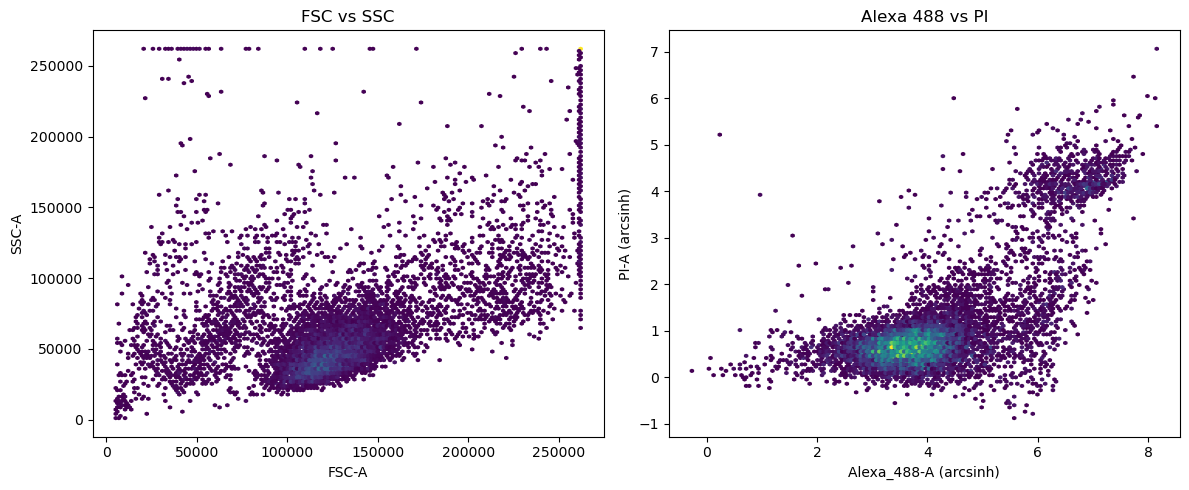

In [5]:
# Using df (CSV data) — substitute `events` for .fcs data
data = df.copy()

# Fluorescence spans several decades and has values below zero, so plot and gate
# it on an arcsinh scale. A cofactor of about 150 suits conventional flow.
cofactor = 150
data["Alexa_488_t"] = np.arcsinh(data["Alexa_488-A"] / cofactor)
data["PI_t"] = np.arcsinh(data["PI-A"] / cofactor)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hexbin(data["FSC-A"], data["SSC-A"], gridsize=150, cmap="viridis", mincnt=1)
axes[0].set_xlabel("FSC-A")
axes[0].set_ylabel("SSC-A")
axes[0].set_title("FSC vs SSC")

axes[1].hexbin(data["Alexa_488_t"], data["PI_t"], gridsize=150, cmap="viridis", mincnt=1)
axes[1].set_xlabel("Alexa_488-A (arcsinh)")
axes[1].set_ylabel("PI-A (arcsinh)")
axes[1].set_title("Alexa 488 vs PI")

plt.tight_layout()
plt.show()

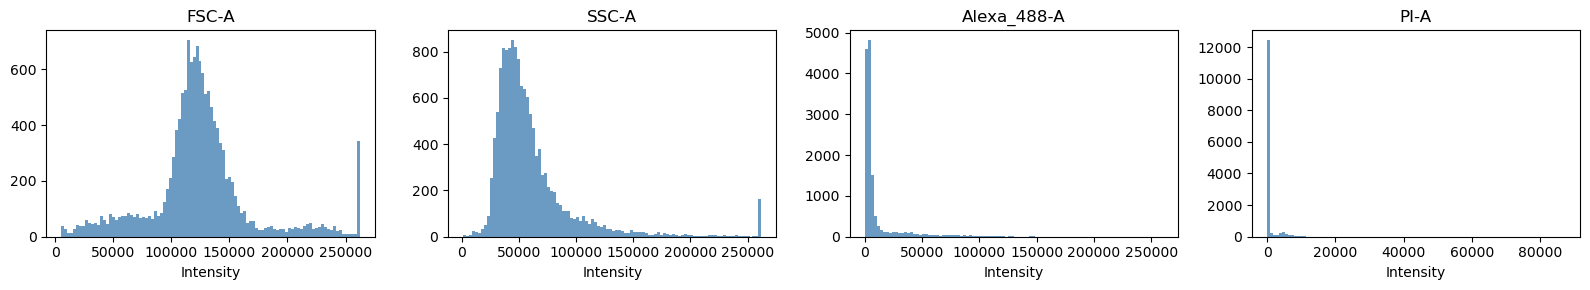

In [6]:
raw_channels = ["FSC-A", "SSC-A", "Alexa_488-A", "PI-A"]
fig, axes = plt.subplots(1, len(raw_channels), figsize=(4 * len(raw_channels), 3))
for ax, col in zip(axes, raw_channels):
    ax.hist(data[col], bins=100, color="steelblue", alpha=0.8)
    ax.set_title(col)
    ax.set_xlabel("Intensity")
plt.tight_layout()
plt.show()

## 5. Gating

Same gates as notebook 01. There are no controls in this file, so the fluorescence cutoffs are judged by eye from the density and don't define true positives.

In [7]:
# Scatter gate
fsc_min, fsc_max = 50000, 250000
ssc_max = 200000
pi_max = 500       # PI-low = live
alexa_min = 16000  # Alexa 488+

mask_scatter = (data["FSC-A"] > fsc_min) & (data["FSC-A"] < fsc_max) & (data["SSC-A"] < ssc_max)
mask_live = mask_scatter & (data["PI-A"] < pi_max)
mask_positive = mask_live & (data["Alexa_488-A"] > alexa_min)

print(f"Total: {len(data)}")
print(f"Scatter gate: {mask_scatter.sum()}")
print(f"Live (PI-): {mask_live.sum()}")
print(f"Alexa 488+: {mask_positive.sum()}")

Total: 13982
Scatter gate: 12784
Live (PI-): 11634
Alexa 488+: 498


## 6. UMAP & Clustering

In [8]:
gated = data[mask_live].copy()
channels = ["FSC-A", "SSC-A", "Alexa_488_t", "PI_t"]
mat = gated[channels].values

scaler = StandardScaler()
mat_scaled = scaler.fit_transform(mat)

# Subsample if large
np.random.seed(42)
n_sub = min(len(mat_scaled), 10000)
idx = np.random.choice(len(mat_scaled), n_sub, replace=False)
mat_sub = mat_scaled[idx]

# UMAP
reducer = umap.UMAP(n_neighbors=15, min_dist=0.2, random_state=42, n_jobs=1)
embedding = reducer.fit_transform(mat_sub)

# Clustering
km = KMeans(n_clusters=4, n_init=25, random_state=42)
clusters = km.fit_predict(mat_sub)

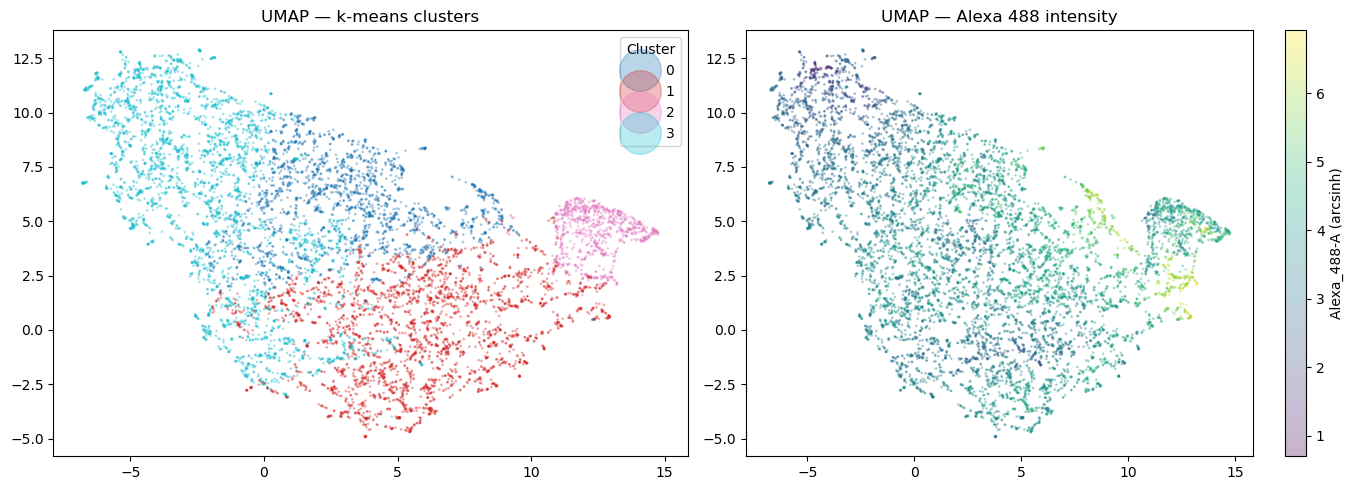

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

scatter = axes[0].scatter(embedding[:, 0], embedding[:, 1],
                           c=clusters, cmap="tab10", s=1, alpha=0.3)
axes[0].set_title("UMAP — k-means clusters")
axes[0].legend(*scatter.legend_elements(), title="Cluster", markerscale=5)

scatter2 = axes[1].scatter(embedding[:, 0], embedding[:, 1],
                            c=mat[idx, 2], cmap="viridis", s=1, alpha=0.3)  # Alexa 488
axes[1].set_title("UMAP — Alexa 488 intensity")
plt.colorbar(scatter2, ax=axes[1], label="Alexa_488-A (arcsinh)")

plt.tight_layout()
plt.show()

## 7. Cluster summary

In [10]:
gated_sub = gated.iloc[idx].copy()
gated_sub["cluster"] = clusters

summary = gated_sub.groupby("cluster")[channels].median()
summary["n_events"] = gated_sub.groupby("cluster").size()
summary

,FSC-A,SSC-A,Alexa_488_t,PI_t,n_events
cluster,,,,,
0,123267.0,47853.4,4.052683,0.362636,2197
1,131360.5,57606.3,3.939411,0.865398,3246
2,206153.0,96707.0,4.397753,1.153955,851
3,116850.0,37746.1,3.186492,0.548981,3706


## 8. Save results

In [11]:
out_dir = Path("../data/results")
out_dir.mkdir(exist_ok=True)

gated_sub.to_csv(out_dir / "05_gated_clustered.csv", index=False)
summary.to_csv(out_dir / "05_cluster_summary.csv")
print(f"Saved to {out_dir}")


Saved to ../data/results
